## 1. Librerías y GPU

In [27]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(len(gpus), "Physical GPUs,", len(tf.config.list_logical_devices('GPU')), "Logical GPUs")
    except RuntimeError as e:
        print(e)
else:
    print("Sin GPU (no es necesaria para este dataset, entrena rápido en CPU)")

1 Physical GPUs, 1 Logical GPUs


## 2. Función para graficar curvas de aprendizaje

In [28]:
def plot_learning_curve(history):
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('Accuracy Curves')
    plt.xlabel('Época')
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.xlabel('Época')
    plt.legend()
    plt.show()

## 3. Cargar el dataset


In [29]:
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = next(iter(uploaded))
except ImportError:
    CSV_PATH = "fitness_poses_csvs_out_full_list__1_.csv"

# El CSV no trae encabezado: col 0 = imagen, col 1 = etiqueta, cols 2..100 = 33 landmarks (x, y, z)
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.iloc[:3, :8]

Saving fitness_poses_csvs_out_full_list (1).csv to fitness_poses_csvs_out_full_list (1).csv
(1424, 101)


,0,1,2,3,4,5,6,7
0,01421731.jpg,knee_raises_down,226.30034,321.50558,-397.16367,238.72528,305.45117,-403.60820
1,02401425.jpg,knee_raises_down,300.15940,326.38544,-260.99380,308.67630,312.77313,-278.50183
2,03270295.jpg,knee_raises_down,241.66364,284.34467,-171.29659,250.13864,270.94520,-199.71988


In [30]:
coord_names = [f"{ax}{i}" for i in range(33) for ax in ("x", "y", "z")]
df.columns = ["imagen", "etiqueta"] + coord_names

print("Valores nulos:", df.isna().sum().sum())
print("Imágenes duplicadas:", df['imagen'].duplicated().sum())
print()
df['etiqueta'].value_counts()

Valores nulos: 0
Imágenes duplicadas: 0



,count
etiqueta,
lateral_raises_down,135
lateral_raises_up,126
knee_raises_up,125
shoulder_press_down,119
knee_raises_down,117
shoulder_flexion_up,114
shoulder_press_up,106
leg_raises_up,106
leg_raises_down,100


## 4. Exploración de las clases
La etiqueta combina **ejercicio** y **fase** (`up` / `down`). Las separamos para analizarlas, aunque el modelo se entrena con la etiqueta completa (13 clases).

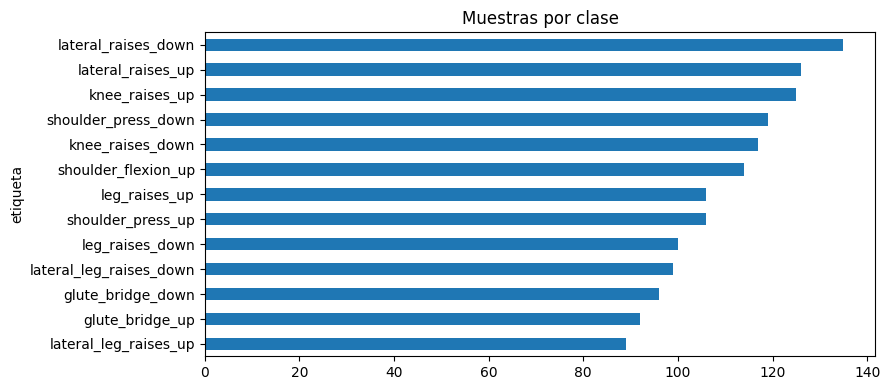

fase,down,up
ejercicio,,
glute_bridge,96.0,92.0
knee_raises,117.0,125.0
lateral_leg_raises,99.0,89.0
lateral_raises,135.0,126.0
leg_raises,100.0,106.0
shoulder_flexion,NaN,114.0
shoulder_press,119.0,106.0


In [31]:
df['ejercicio'] = df['etiqueta'].str.rsplit('_', n=1).str[0]
df['fase'] = df['etiqueta'].str.rsplit('_', n=1).str[1]

plt.figure(figsize=(9, 4))
df['etiqueta'].value_counts().sort_values().plot(kind='barh')
plt.title("Muestras por clase")
plt.tight_layout()
plt.show()

df.groupby('ejercicio')['fase'].value_counts().unstack()

## 5. Preparar los datos
1. Convertimos cada fila a un arreglo `(33, 3)`.
2. **Normalización de pose:** restamos el centro de la cadera (así la pose queda centrada en el origen) y dividimos entre la longitud del torso (así no importa la distancia a la cámara).

Índices MediaPipe: hombros = 11 y 12, caderas = 23 y 24.

In [32]:
X_raw = df[coord_names].to_numpy(dtype=np.float32).reshape(-1, 33, 3)

def normalizar_pose(poses):
    """poses: (N, 33, 3) -> (N, 99) centradas en la cadera y escaladas por el torso."""
    poses = poses.copy()
    cadera = (poses[:, 23] + poses[:, 24]) / 2          # (N, 3)
    hombro = (poses[:, 11] + poses[:, 12]) / 2          # (N, 3)
    poses = poses - cadera[:, None, :]
    torso = np.linalg.norm(hombro - cadera, axis=1)     # (N,)
    poses = poses / np.maximum(torso, 1e-6)[:, None, None]
    return poses.reshape(len(poses), -1)

X = normalizar_pose(X_raw)

encoder = LabelEncoder()
y = encoder.fit_transform(df['etiqueta'])
class_names = list(encoder.classes_)
n_classes = len(class_names)

print("X:", X.shape, "| y:", y.shape, "| clases:", n_classes)
print("Rango antes :", X_raw.min(), "a", X_raw.max())
print("Rango después:", X.min().round(2), "a", X.max().round(2))

X: (1424, 99) | y: (1424,) | clases: 13
Rango antes : -1456.866 a 3231.2917
Rango después: -5.21 a 4.78


## 6. División Train / Validación / Test
70 % / 15 % / 15 %, **estratificada** para que cada conjunto tenga la misma proporción de clases (importante porque el dataset es pequeño).

In [33]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp
)

# Guardamos también las poses crudas del test (las usaremos en el experimento de robustez)
_, tmp_raw, _, _ = train_test_split(X_raw, y, test_size=0.30, random_state=42, stratify=y)
_, X_test_raw, _, _ = train_test_split(tmp_raw, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)

X_train.shape, X_val.shape, X_test.shape

((996, 99), (214, 99), (214, 99))

## 7. Visualizar una pose
Dibujamos el esqueleto normalizado de algunas muestras para confirmar que la normalización tiene sentido.

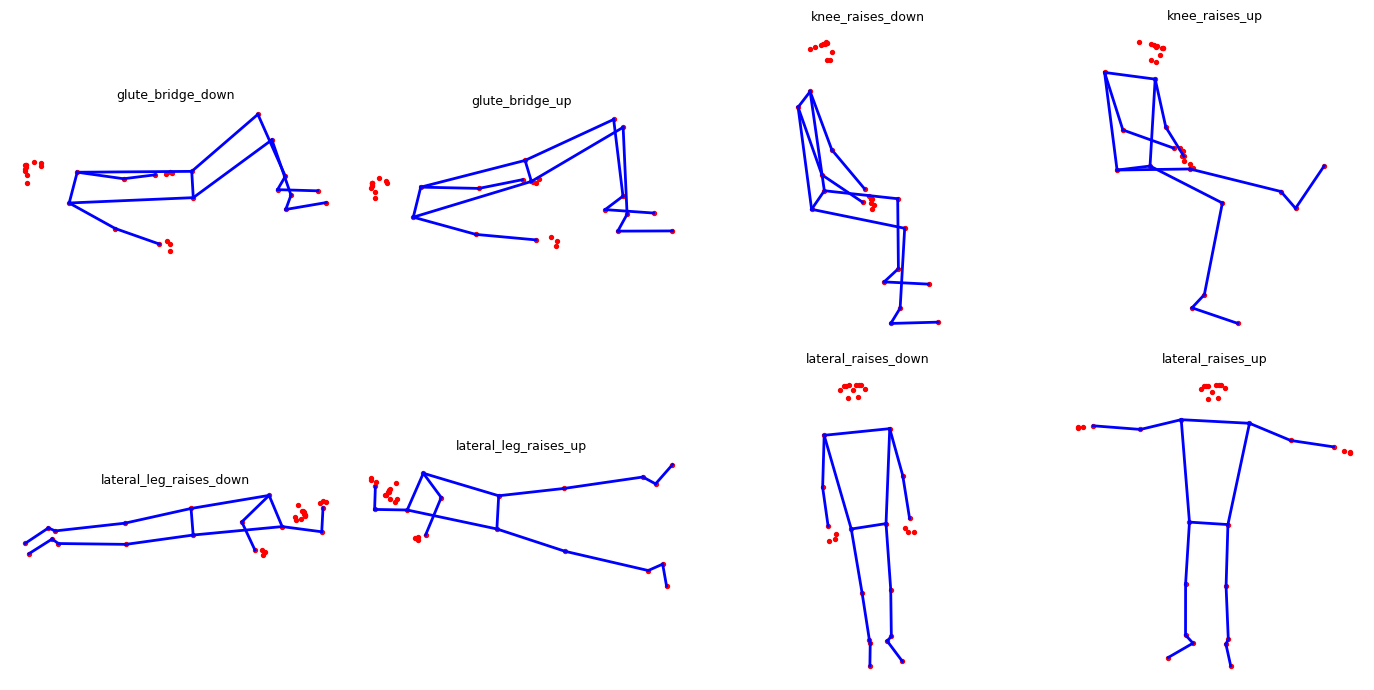

In [34]:
# Conexiones principales del esqueleto de MediaPipe
CONEXIONES = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),(23,24),
              (23,25),(25,27),(24,26),(26,28),(27,29),(29,31),(28,30),(30,32)]

def dibujar_pose(vec99, ax, titulo=""):
    p = vec99.reshape(33, 3)
    for a, b in CONEXIONES:
        ax.plot([p[a,0], p[b,0]], [p[a,1], p[b,1]], 'b-', lw=2)
    ax.scatter(p[:,0], p[:,1], s=8, c='r')
    ax.invert_yaxis()          # en imagen, y crece hacia abajo
    ax.set_aspect('equal')
    ax.set_title(titulo, fontsize=9)
    ax.axis('off')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, clase in zip(axes.ravel(), class_names[:8]):
    idx = np.where(y_train == encoder.transform([clase])[0])[0][0]
    dibujar_pose(X_train[idx], ax, clase)
plt.tight_layout()
plt.show()